In [2]:
import tensorflow as tf
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("TensorFlow Version:", tf.__version__)
print("NumPy Version:", np.__version__)
print("Pandas Version:", pd.__version__)

TensorFlow Version: 2.21.0
NumPy Version: 2.4.6
Pandas Version: 3.1.1


In [3]:
from pathlib import Path
import joblib
import unicodedata
import re

from sklearn.model_selection import StratifiedGroupKFold

# Load original dataset
data_path = Path("../data/xfact_train.csv")
df = pd.read_csv(data_path)

# Normalize multilingual claims
df["claim_normalized"] = df["claim"].apply(
    lambda text: re.sub(
        r"\s+",
        " ",
        unicodedata.normalize("NFC", text)
    ).strip()
)

# Load existing label encoder
models_dir = Path("../models")
label_encoder = joblib.load(
    models_dir / "label_encoder.pkl"
)

# Encode labels
y = label_encoder.transform(df["label"])

# Recreate the same group-safe train/test split
splitter = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

train_idx, test_idx = next(
    splitter.split(
        df["claim_normalized"],
        y,
        groups=df["claim_normalized"]
    )
)

X_train = df.iloc[train_idx]["claim_normalized"].to_numpy()
X_test = df.iloc[test_idx]["claim_normalized"].to_numpy()

y_train = y[train_idx]
y_test = y[test_idx]

print("Training records:", len(X_train))
print("Testing records:", len(X_test))
print("Number of classes:", len(label_encoder.classes_))
print("Dataset loaded successfully!")

Training records: 15263
Testing records: 3816
Number of classes: 7
Dataset loaded successfully!


In [4]:
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

# Tokenizer configuration
vocab_size = 30000
max_length = 100

tokenizer = Tokenizer(
    num_words=vocab_size,
    oov_token="<OOV>",
    char_level=True
)

# Learn characters from training data only
tokenizer.fit_on_texts(X_train)

# Convert claims into sequences
X_train_sequences = tokenizer.texts_to_sequences(X_train)
X_test_sequences = tokenizer.texts_to_sequences(X_test)

# Pad sequences to equal length
X_train_padded = pad_sequences(
    X_train_sequences,
    maxlen=max_length,
    padding="post",
    truncating="post"
)

X_test_padded = pad_sequences(
    X_test_sequences,
    maxlen=max_length,
    padding="post",
    truncating="post"
)

print("Training shape:", X_train_padded.shape)
print("Testing shape:", X_test_padded.shape)
print("Vocabulary size:", len(tokenizer.word_index))

Training shape: (15263, 100)
Testing shape: (3816, 100)
Vocabulary size: 375


In [5]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Embedding,
    Bidirectional,
    LSTM,
    Dense,
    Dropout
)

num_classes = len(label_encoder.classes_)

dl_model = Sequential([
    Embedding(
        input_dim=vocab_size,
        output_dim=64,
        input_length=max_length,
        mask_zero=True
    ),

    Bidirectional(
        LSTM(64)
    ),

    Dropout(0.4),

    Dense(64, activation="relu"),

    Dropout(0.3),

    Dense(num_classes, activation="softmax")
])

dl_model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

dl_model.summary()

c:\Users\RAM\anaconda3\Allah\envs\truthlens_env\Lib\site-packages\keras\src\layers\core\embedding.py:123: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional (Bidirectional)   │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

In [6]:
from tensorflow.keras.callbacks import EarlyStopping

early_stop = EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

history = dl_model.fit(
    X_train_padded,
    y_train,
    validation_split=0.15,
    epochs=15,
    batch_size=64,
    callbacks=[early_stop],
    verbose=1
)

Epoch 1/15
203/203 ━━━━━━━━━━━━━━━━━━━━ 21s 75ms/step - accuracy: 0.4110 - loss: 1.4776 - val_accuracy: 0.3415 - val_loss: 1.6305
Epoch 2/15
203/203 ━━━━━━━━━━━━━━━━━━━━ 15s 71ms/step - accuracy: 0.4363 - loss: 1.3520 - val_accuracy: 0.3541 - val_loss: 1.6335
Epoch 3/15
203/203 ━━━━━━━━━━━━━━━━━━━━ 14s 70ms/step - accuracy: 0.4522 - loss: 1.3177 - val_accuracy: 0.3563 - val_loss: 1.6214
Epoch 4/15
203/203 ━━━━━━━━━━━━━━━━━━━━ 15s 71ms/step - accuracy: 0.4587 - loss: 1.2956 - val_accuracy: 0.3585 - val_loss: 1.6797
Epoch 5/15
203/203 ━━━━━━━━━━━━━━━━━━━━ 15s 72ms/step - accuracy: 0.4674 - loss: 1.2734 - val_accuracy: 0.3537 - val_loss: 1.6850
Epoch 6/15
203/203 ━━━━━━━━━━━━━━━━━━━━ 14s 71ms/step - accuracy: 0.4734 - loss: 1.2638 - val_accuracy: 0.3607 - val_loss: 1.7435


In [7]:
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    classification_report
)

# Generate predictions
dl_probabilities = dl_model.predict(X_test_padded)

dl_pred = np.argmax(dl_probabilities, axis=1)

# Calculate metrics
dl_accuracy = accuracy_score(y_test, dl_pred)

dl_balanced_accuracy = balanced_accuracy_score(
    y_test, dl_pred
)

dl_macro_f1 = f1_score(
    y_test,
    dl_pred,
    average="macro"
)

print("Deep Learning Model Results")
print("-" * 40)

print(f"Accuracy: {dl_accuracy:.4f}")
print(f"Balanced Accuracy: {dl_balanced_accuracy:.4f}")
print(f"Macro F1: {dl_macro_f1:.4f}")

print("\nClassification Report:\n")

print(
    classification_report(
        y_test,
        dl_pred,
        labels=np.arange(len(label_encoder.classes_)),
        target_names=label_encoder.classes_,
        zero_division=0
    )
)

120/120 ━━━━━━━━━━━━━━━━━━━━ 2s 13ms/step
Deep Learning Model Results
----------------------------------------
Accuracy: 0.4479
Balanced Accuracy: 0.2521
Macro F1: 0.2415

Classification Report:

                                precision    recall  f1-score   support

complicated/hard to categorise       0.00      0.00      0.00       108
                         false       0.45      0.77      0.57      1503
                  mostly false       0.46      0.42      0.44       170
                   mostly true       0.00      0.00      0.00       276
                         other       0.00      0.00      0.00        71
        partly true/misleading       0.50      0.22      0.30       872
                          true       0.40      0.35      0.38       816

                      accuracy                           0.45      3816
                     macro avg       0.26      0.25      0.24      3816
                  weighted avg       0.40      0.45      0.39      3816



In [8]:
from sklearn.metrics import confusion_matrix

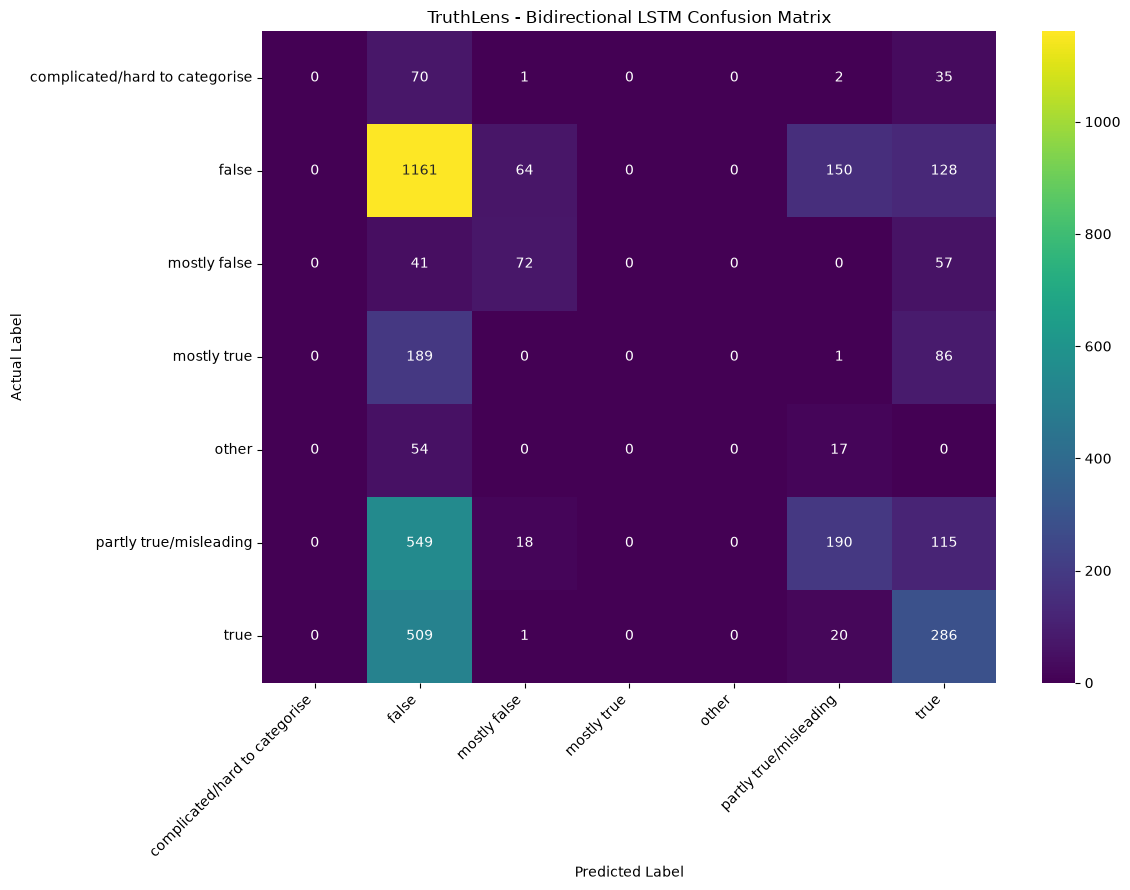

In [9]:
dl_cm = confusion_matrix(y_test, dl_pred)

plt.figure(figsize=(12, 9))

sns.heatmap(
    dl_cm,
    annot=True,
    fmt="d",
    cmap="viridis",
    xticklabels=label_encoder.classes_,
    yticklabels=label_encoder.classes_
)

plt.title("TruthLens - Bidirectional LSTM Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

In [10]:
comparison_df = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "LinearSVC",
        "Tuned LinearSVC",
        "Bidirectional LSTM"
    ],
    "Accuracy": [
        0.3692,
        0.4340,
        0.4374,
        dl_accuracy
    ],
    "Balanced Accuracy": [
        0.4475,
        0.3834,
        0.4462,
        dl_balanced_accuracy
    ],
    "Macro F1": [
        0.3224,
        0.3614,
        0.3658,
        dl_macro_f1
    ]
})

comparison_df

,Model,Accuracy,Balanced Accuracy,Macro F1
0,Logistic Regression,0.369200,0.447500,0.322400
1,LinearSVC,0.434000,0.383400,0.361400
2,Tuned LinearSVC,0.437400,0.446200,0.365800
3,Bidirectional LSTM,0.447851,0.252052,0.241498


In [11]:
import plotly.express as px

comparison_long = comparison_df.melt(
    id_vars="Model",
    var_name="Metric",
    value_name="Score"
)

fig = px.bar(
    comparison_long,
    x="Model",
    y="Score",
    color="Metric",
    barmode="group",
    text_auto=".3f",
    title="TruthLens — Machine Learning vs Deep Learning"
)

fig.update_layout(
    template="plotly_white",
    height=600,
    width=1100,
    title_x=0.5,
    yaxis_title="Performance Score",
    xaxis_title="Model",
    yaxis=dict(range=[0, 1]),
    legend_title="Evaluation Metrics"
)

fig.show()

In [12]:
from sklearn.utils.class_weight import compute_class_weight

classes = np.unique(y_train)

class_weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=y_train
)

class_weight_dict = dict(
    zip(classes, class_weights)
)

print("Class Weights:")

for class_id, weight in class_weight_dict.items():
    print(
        f"{label_encoder.classes_[class_id]}: {weight:.3f}"
    )

Class Weights:
complicated/hard to categorise: 5.047
false: 0.363
mostly false: 3.216
mostly true: 1.975
other: 7.624
partly true/misleading: 0.625
true: 0.668


In [13]:
improved_model = tf.keras.models.clone_model(dl_model)

improved_model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

improved_history = improved_model.fit(
    X_train_padded,
    y_train,
    validation_split=0.15,
    epochs=15,
    batch_size=64,
    class_weight=class_weight_dict,
    callbacks=[early_stop],
    verbose=1
)

Epoch 1/15
203/203 ━━━━━━━━━━━━━━━━━━━━ 21s 79ms/step - accuracy: 0.2368 - loss: 1.6173 - val_accuracy: 0.1882 - val_loss: 1.7965
Epoch 2/15
203/203 ━━━━━━━━━━━━━━━━━━━━ 16s 77ms/step - accuracy: 0.2246 - loss: 1.4497 - val_accuracy: 0.2332 - val_loss: 1.7291
Epoch 3/15
203/203 ━━━━━━━━━━━━━━━━━━━━ 16s 78ms/step - accuracy: 0.2310 - loss: 1.3824 - val_accuracy: 0.2022 - val_loss: 1.7561
Epoch 4/15
203/203 ━━━━━━━━━━━━━━━━━━━━ 16s 78ms/step - accuracy: 0.2429 - loss: 1.3303 - val_accuracy: 0.1847 - val_loss: 1.7679
Epoch 5/15
203/203 ━━━━━━━━━━━━━━━━━━━━ 16s 79ms/step - accuracy: 0.2424 - loss: 1.3130 - val_accuracy: 0.2214 - val_loss: 1.7186
Epoch 6/15
203/203 ━━━━━━━━━━━━━━━━━━━━ 20s 75ms/step - accuracy: 0.2563 - loss: 1.2991 - val_accuracy: 0.2279 - val_loss: 1.7446
Epoch 7/15
203/203 ━━━━━━━━━━━━━━━━━━━━ 15s 73ms/step - accuracy: 0.2575 - loss: 1.2675 - val_accuracy: 0.2197 - val_loss: 1.7209
Epoch 8/15
203/203 ━━━━━━━━━━━━━━━━━━━━ 15s 75ms/step - accuracy: 0.2595 - loss: 1.2578 - 

In [14]:
improved_probabilities = improved_model.predict(
    X_test_padded
)

improved_pred = np.argmax(
    improved_probabilities,
    axis=1
)

improved_accuracy = accuracy_score(
    y_test, improved_pred
)

improved_balanced_accuracy = balanced_accuracy_score(
    y_test, improved_pred
)

improved_macro_f1 = f1_score(
    y_test,
    improved_pred,
    average="macro"
)

print("Improved LSTM Results")
print("-" * 40)

print(f"Accuracy: {improved_accuracy:.4f}")
print(f"Balanced Accuracy: {improved_balanced_accuracy:.4f}")
print(f"Macro F1: {improved_macro_f1:.4f}")

print("\nClassification Report:\n")

print(
    classification_report(
        y_test,
        improved_pred,
        labels=np.arange(len(label_encoder.classes_)),
        target_names=label_encoder.classes_,
        zero_division=0
    )
)

120/120 ━━━━━━━━━━━━━━━━━━━━ 2s 14ms/step
Improved LSTM Results
----------------------------------------
Accuracy: 0.2702
Balanced Accuracy: 0.4092
Macro F1: 0.2570

Classification Report:

                                precision    recall  f1-score   support

complicated/hard to categorise       0.06      0.52      0.11       108
                         false       0.51      0.20      0.29      1503
                  mostly false       0.24      0.80      0.36       170
                   mostly true       0.16      0.27      0.20       276
                         other       0.12      0.58      0.19        71
        partly true/misleading       0.44      0.26      0.32       872
                          true       0.44      0.24      0.31       816

                      accuracy                           0.27      3816
                     macro avg       0.28      0.41      0.26      3816
                  weighted avg       0.42      0.27      0.29      3816



In [15]:
lstm_comparison = pd.DataFrame({
    "Model": [
        "Original LSTM",
        "Class Weighted LSTM"
    ],
    "Accuracy": [
        dl_accuracy,
        improved_accuracy
    ],
    "Balanced Accuracy": [
        dl_balanced_accuracy,
        improved_balanced_accuracy
    ],
    "Macro F1": [
        dl_macro_f1,
        improved_macro_f1
    ]
})

lstm_comparison

,Model,Accuracy,Balanced Accuracy,Macro F1
0,Original LSTM,0.447851,0.252052,0.241498
1,Class Weighted LSTM,0.270178,0.409154,0.256983


In [16]:
lstm_long = lstm_comparison.melt(
    id_vars="Model",
    var_name="Metric",
    value_name="Score"
)

fig = px.bar(
    lstm_long,
    x="Metric",
    y="Score",
    color="Model",
    barmode="group",
    text_auto=".3f",
    title="TruthLens — Original vs Class-Weighted LSTM"
)

fig.update_layout(
    template="plotly_white",
    title_x=0.5,
    height=550,
    yaxis=dict(range=[0, 1]),
    yaxis_title="Performance Score",
    xaxis_title="Evaluation Metric"
)

fig.show()

In [17]:
models_dir = Path("../models")
models_dir.mkdir(exist_ok=True)

# Save original LSTM
dl_model.save(
    models_dir / "original_lstm.keras"
)

# Save improved LSTM
improved_model.save(
    models_dir / "class_weighted_lstm.keras"
)

# Save tokenizer
joblib.dump(
    tokenizer,
    models_dir / "lstm_tokenizer.pkl"
)

print("Both LSTM models and tokenizer saved successfully!")

Both LSTM models and tokenizer saved successfully!


In [18]:
dl_results = pd.DataFrame({
    "Model": [
        "Original LSTM",
        "Class-Weighted LSTM"
    ],
    "Accuracy": [
        dl_accuracy,
        improved_accuracy
    ],
    "Balanced Accuracy": [
        dl_balanced_accuracy,
        improved_balanced_accuracy
    ],
    "Macro F1": [
        dl_macro_f1,
        improved_macro_f1
    ]
})

reports_dir = Path("../reports")
reports_dir.mkdir(exist_ok=True)

dl_results.to_csv(
    reports_dir / "deep_learning_metrics.csv",
    index=False
)

print("Deep Learning metrics saved successfully!")

Deep Learning metrics saved successfully!
